In [1]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_train = trizod_df[~trizod_df["is_test"]]
df_test = trizod_df[trizod_df["is_test"]]

In [ ]:
filename = "train7.csv"

if not os.path.exists(filename):
    fasta_filename = "train.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_train.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "adopt2g-predict",
            "--input",
            fasta_filename,
            "--out",
            filename,
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_std": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

2026-01-10 09:30:44 [INFO] adopt2g.inference: Loading ensemble from /home/michele/workdir/ADOPT2g/models/seed883_n7/manifest.json...
2026-01-10 09:30:44 [INFO] adopt2g.inference:   Ensemble ID: seed883_n7
2026-01-10 09:30:44 [INFO] adopt2g.inference:   Ensemble size: 7
2026-01-10 09:30:44 [INFO] adopt2g.inference:   Calibration factor: 3.3173
2026-01-10 09:30:44 [INFO] adopt2g.inference:   Loading ESM model to cuda...
2026-01-10 09:30:45 [WARNING] adopt2g.embeddings: Flash Attention 2 not available (libcudart.so.12: cannot open shared object file: No such file or directory), falling back to sdpa attention


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(


2026-01-10 09:30:45 [INFO] adopt2g.inference:   Loading 7 ST models...
2026-01-10 09:30:45 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:30:45 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_0/st
2026-01-10 09:30:46 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:30:46 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_1/st
2026-01-10 09:30:46 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:30:46 [INFO] sentence_transformers.SentenceTransformer: Load pretrained SentenceTransformer: /home/michele/workdir/ADOPT2g/models/seed883_n7/member_2/st
2026-01-10 09:30:46 [INFO] sentence_transformers.SentenceTransformer: Use pytorch device_name: cuda:0
2026-01-10 09:30:46 

Processing:   0%|          | 0/6707 [00:00<?, ?it/s]
                                                    
Batches: 100%|██████████| 1/1 [00:00<00:00,  8.79it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 58.15it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 59.88it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 62.68it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 61.85it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 59.85it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00, 65.31it/s]

Batches: 100%|██████████| 210/210 [00:04<00:00, 42.62it/s]

Batches: 100%|██████████| 210/210 [00:04<00:00, 43.35it/s] 

Batches: 100%|██████████| 210/210 [00:04<00:00, 43.88it/s] 

Batches: 100%|██████████| 210/210 [00:04<00:00, 43.38it/s] 

Batches: 100%|██████████| 210/210 [00:05<00:00, 41.26it/s] 

Batches: 100%|██████████| 210/210 [00:04<00:00, 43.92it/s] 

100%|██████████| 1/1 [02:25<00:00, 145.33s/it]


2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict: Combining chunks...
2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict: Results saved to train7.csv
2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict: Columns: label, sequence, mean_gscore, mean_gscore_std, gscores, gscores_std
2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict:   - mean_gscore_std: calibrated std across ensemble members of per-member mean_gscore
2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict:   - gscores_std: calibrated per-residue std across ensemble members (JSON array)
2026-01-10 09:33:12 [INFO] adopt2g.scripts.predict: (Use json.loads() to parse JSON array columns)


,sequence,mean_gscore,mean_gscore_std,gscores,gscores_std
label,,,,,
9_1_1_1,XQHADPICNKPCKTHDDCSGAWFCQACWNSARTCGPYVG,0.138672,0.013227,"[nan, 0.21630859375, 0.306640625, 0.2856445312...","[nan, 0.08551025390625, 0.10760498046875, 0.09..."
26_1_1_1,MADPNRFRGKDLPVLDQLTDPP,0.596191,0.307340,"[0.42822265625, 0.53369140625, 0.4541015625, 0...","[0.41943359375, 0.2301025390625, 0.25268554687..."
32_1_1_1,MKPVTLYDVAEYAGVSYQTVSRVVNQASHVSAKTREKVEAAMAELN...,0.116394,0.023129,"[0.227783203125, 0.2454833984375, 0.1821289062...","[0.14697265625, 0.1279296875, 0.12115478515625..."
39_1_1_1,XMDPNCSCATDGSCSCAGSCKCKQCKKTSCKKSCCSCCPVGCAKCS...,0.177246,0.073609,"[nan, 0.31640625, 0.302490234375, 0.2280273437...","[nan, 0.177001953125, 0.1639404296875, 0.05203..."
41_1_1_1,VFCTCRGFLCGSGERASGSCTINGVRHTLCCRR,0.171753,0.127267,"[0.30859375, 0.22509765625, 0.1654052734375, 0...","[0.1925048828125, 0.1114501953125, 0.120544433..."
...,...,...,...,...,...
53396_1_1_1,GSDQSENVDRGAGSIREAGGAFGKREQAEEERYFRAQSREQLAALK...,0.328613,0.037032,"[0.4423828125, 0.391845703125, 0.446533203125,...","[0.6494140625, 0.509765625, 0.54443359375, 0.4..."
53398_1_1_1,PAGQPERTLESLLAHLQEQHGLRVRILLHGSALLYAAGWSPEKQAQ...,0.122803,0.052515,"[0.352783203125, 0.30029296875, 0.29248046875,...","[0.290771484375, 0.257568359375, 0.20788574218..."
53400_1_1_1,KCGSLGNIHHKPGGGQVEVKSEKLDFKDRVQSKIGSLDNITHVPGG...,0.847168,0.018724,"[0.6591796875, 0.7822265625, 0.84814453125, 0....","[0.27294921875, 0.1622314453125, 0.11151123046..."


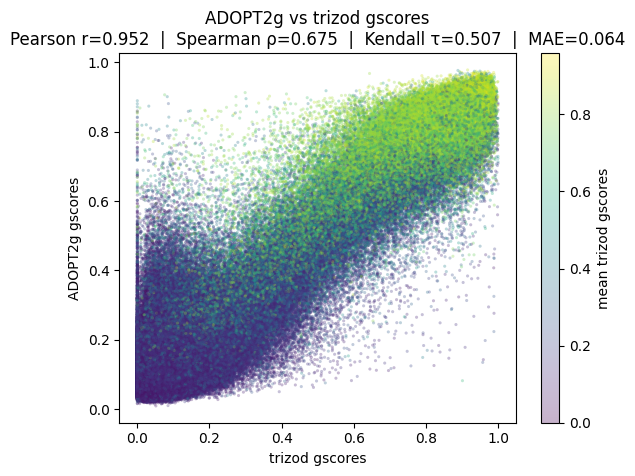

In [4]:
from scipy.stats import kendalltau, pearsonr, spearmanr

mean_trizod_gscores = np.repeat(df_train["gscores"].apply(np.nanmean).values, df_train["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_train["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()


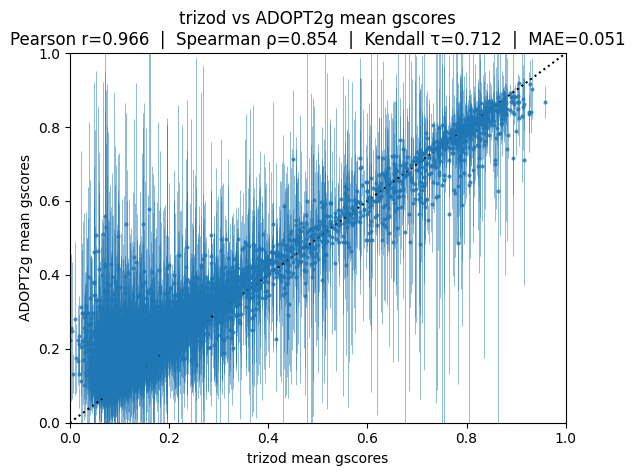

In [5]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_train["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_train["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_train["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_train["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_train["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=df_inferred["mean_gscore_std"],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


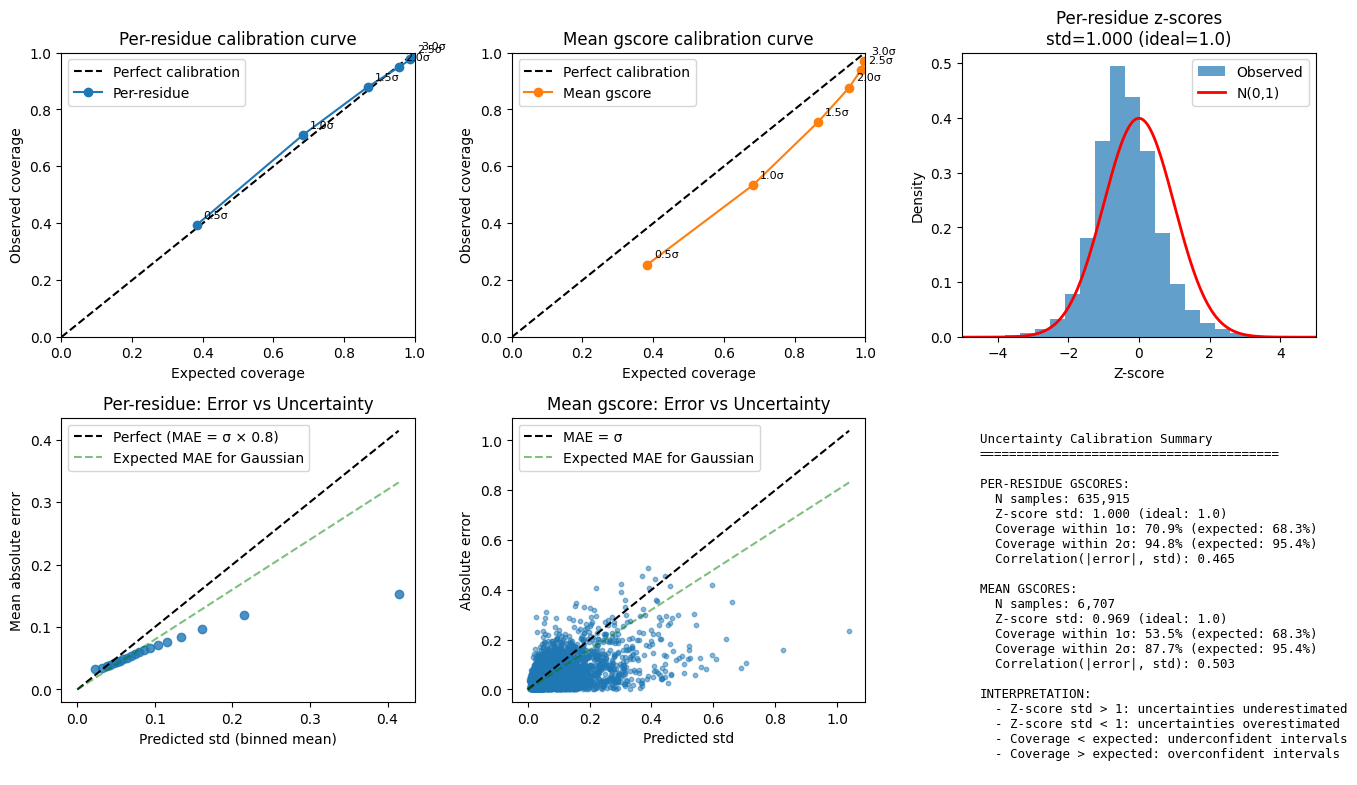

In [6]:
# Uncertainty calibration analysis
# For well-calibrated uncertainties, ~68% of true values should fall within ±1σ, ~95% within ±2σ

# --- Per-residue uncertainty calibration ---
trizod_gscores = np.concatenate(df_train["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_std = np.concatenate(df_inferred["gscores_std"].values)

# Mask for valid values
mask = np.isfinite(trizod_gscores) & np.isfinite(pred_gscores) & np.isfinite(pred_gscores_std) & (pred_gscores_std > 0)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
pred_stds = pred_gscores_std[mask]

# Compute z-scores (normalized residuals)
residuals = true_vals - pred_vals
z_scores = residuals / pred_stds

# Calibration: fraction of points within n standard deviations
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
expected_coverage = 2 * (
    0.5 - (1 - np.vectorize(lambda x: __import__("scipy.stats", fromlist=["norm"]).norm.cdf(x))(n_sigmas))
)
# Simpler: expected for Gaussian
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])
observed_coverage_residue = np.array([np.mean(np.abs(z_scores) <= n) for n in n_sigmas])

# --- Mean gscore uncertainty calibration ---
true_mean = df_train["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_std = df_inferred["mean_gscore_std"].values

mask_mean = np.isfinite(true_mean) & np.isfinite(pred_mean) & np.isfinite(pred_mean_std) & (pred_mean_std > 0)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = residuals_mean / pred_mean_std[mask_mean]

observed_coverage_mean = np.array([np.mean(np.abs(z_scores_mean) <= n) for n in n_sigmas])

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Z-score")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue z-scores\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted std - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by predicted std
n_bins = 20
std_bins = np.percentile(pred_stds, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
mean_stds = []
for i in range(n_bins):
    in_bin = (pred_stds >= std_bins[i]) & (pred_stds < std_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(pred_stds[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
        mean_stds.append(np.mean(pred_stds[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="Perfect (MAE = σ × 0.8)")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted std - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
ax.scatter(pred_mean_std[mask_mean], abs_errors_mean, alpha=0.5, s=10)
max_val = max(pred_mean_std[mask_mean].max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = σ")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary
{"=" * 40}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Z-score std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors, pred_stds)[0, 1]:.3f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Z-score std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors_mean, pred_mean_std[mask_mean])[0, 1]:.3f}

INTERPRETATION:
  - Z-score std > 1: uncertainties underestimated
  - Z-score std < 1: uncertainties overestimated
  - Coverage < expected: underconfident intervals
  - Coverage > expected: overconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()
